# 01. Exploratory Data Analysis (EDA) — Bank Telemarketing Dataset

**Course**: CP322 Machine Learning Project  
**Dataset**: UCI Bank Marketing with Social & Economic Context ([Moro, Cortez & Rita, 2014](http://dx.doi.org/10.1016/j.dss.2014.03.001))  
**Core Research Question**:
> *"Only about 12% of customers say yes. Compare three ways of handling this: (1) do nothing, (2) give the rare class more weight when training, and (3) resample the training data. Report which works best and what each one costs."*

### Objectives of This Notebook
1. Verify dataset dimensions, data types, exact duplicates, and target imbalance across `bank-additional-full.csv` and the 10% debug file (`bank-additional.csv`).
2. Audit **data leakage** (`duration`) and document why it must be removed.
3. Investigate `"unknown"` missing values and sentinel values (`pdays = 999`) to guide feature engineering.
4. Explore categorical conversion patterns, numeric distributions, and **multicollinearity** among macroeconomic indicators.
5. Check post-One-Hot-Encoding dimensionality to decide whether feature selection is needed, and preview sample sizes under a leakage-free train/test split and resampling.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Plot styling (pure matplotlib, no seaborn required)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
plt.rcParams["font.size"] = 10

COLORS = {
    "no": "#4C78A8",
    "yes": "#E45756",
    "accent": "#F58518",
    "neutral": "#72B7B2",
    "muted": "#999999",
}

# Resolve data directory whether run from project root or notebooks/
DATA_DIR = Path("data") if Path("data/bank-additional-full.csv").exists() else Path("../data")
FULL_PATH = DATA_DIR / "bank-additional-full.csv"
SAMPLE_PATH = DATA_DIR / "bank-additional.csv"

df_full = pd.read_csv(FULL_PATH, sep=";")
df_10 = pd.read_csv(SAMPLE_PATH, sep=";")

print(f"Loaded full dataset:   {df_full.shape[0]:,} rows x {df_full.shape[1]} columns")
print(f"Loaded 10% debug data: {df_10.shape[0]:,} rows x {df_10.shape[1]} columns")

: 

---
## 1. Basic Data Overview & Quality Checks

In [ ]:
df_full.head()

: 

In [ ]:
# Data types, NaNs, and exact duplicates
n_dups = df_full.duplicated().sum()
n_nans = df_full.isna().sum().sum()

print(f"Total NaN values in full dataset: {n_nans}")
print(f"Exact duplicate rows in full dataset: {n_dups} ({n_dups / len(df_full) * 100:.3f}%)")
print(f"Unique rows after deduplication: {len(df_full) - n_dups:,}")

dtype_summary = pd.DataFrame({
    "dtype": df_full.dtypes.astype(str),
    "n_unique": df_full.nunique(),
    "n_unknown": [(df_full[c] == "unknown").sum() if df_full[c].dtype == "object" else 0 for c in df_full.columns],
    "sample_values": [df_full[c].unique()[:4].tolist() for c in df_full.columns],
})
dtype_summary

: 

**Takeaway**:
- There are **zero `NaN` values** — all missing categorical values are encoded as the string `"unknown"`.
- There are **12 exact duplicate rows**. We should drop exact duplicates **before** performing the train/test split so identical records cannot appear in both training and test sets.

---
## 2. Target Variable (`y`) & Class Imbalance

In [ ]:
def target_summary(df, name):
    counts = df["y"].value_counts()
    pcts = df["y"].value_counts(normalize=True) * 100
    ratio = counts["no"] / counts["yes"]
    return pd.Series({
        "Total Rows": len(df),
        "No (0)": counts["no"],
        "No (%)": round(pcts["no"], 2),
        "Yes (1)": counts["yes"],
        "Yes (%)": round(pcts["yes"], 2),
        "Imbalance Ratio (No:Yes)": round(ratio, 2),
    }, name=name)

summary_df = pd.DataFrame([
    target_summary(df_full, "bank-additional-full (raw)"),
    target_summary(df_full.drop_duplicates(), "bank-additional-full (deduped)"),
    target_summary(df_10, "bank-additional (10% debug)"),
])
summary_df

: 

In [ ]:
counts = df_full["y"].value_counts()
pcts = df_full["y"].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(6.5, 4.2))
bars = ax.bar(
    ["No (Did Not Subscribe)", "Yes (Subscribed)"],
    [counts["no"], counts["yes"]],
    color=[COLORS["no"], COLORS["yes"]],
    width=0.55,
    edgecolor="white",
)

for bar, cnt, pct in zip(bars, [counts["no"], counts["yes"]], [pcts["no"], pcts["yes"]]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 600,
        f"{cnt:,}\n({pct:.2f}%)",
        ha="center",
        va="bottom",
        fontweight="bold",
    )

ax.set_ylim(0, counts["no"] * 1.16)
ax.set_ylabel("Number of Clients")
ax.set_title("Target Class Distribution (y) — Imbalance Ratio 7.88 : 1", pad=12, fontweight="bold")
plt.tight_layout()
plt.show()

: 

**Takeaway**:
- Only **11.27%** of clients subscribed (`yes`), versus **88.73%** `no` (imbalance ratio **7.88 : 1**).
- A trivial majority-class baseline predicting `"no"` for every client achieves **88.73% accuracy** but **0% recall**. Therefore, **PR-AUC (Average Precision)**, **ROC-AUC**, **F1-score**, **Precision**, and **Recall** must be our primary evaluation metrics.

---
## 3. Data Leakage Audit: `duration`

From `bank-additional-names.txt`:
> *"This attribute highly affects the output target (e.g., if duration=0 then y='no'). Yet, the duration is not known before a call is performed. Also, after the end of the call y is obviously known. Thus, this input should only be included for benchmark purposes and should be discarded if the intention is to have a realistic predictive model."*

Call duration (seconds) by target class:
Rows with duration == 0: 4 (yes count: 0)


,count,mean,median,std,min,max
y,,,,,,
no,36548,220.84,163.5,207.10,0,4918
yes,4640,553.19,449.0,401.17,37,4199


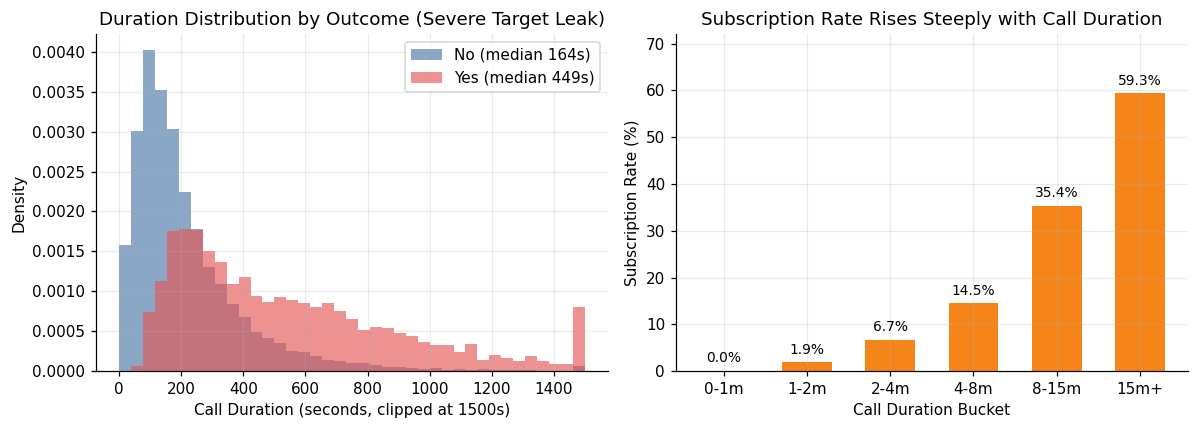

In [6]:
dur_stats = df_full.groupby("y")["duration"].agg(["count", "mean", "median", "std", "min", "max"]).round(2)
print("Call duration (seconds) by target class:")
display(dur_stats)
print(f"Rows with duration == 0: {(df_full['duration'] == 0).sum()} (yes count: {((df_full['duration'] == 0) & (df_full['y'] == 'yes')).sum()})")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.0))

# Histogram clipped at 1500s for readability
bins = np.linspace(0, 1500, 40)
axes[0].hist(df_full.loc[df_full["y"] == "no", "duration"].clip(upper=1500), bins=bins, density=True, alpha=0.65, color=COLORS["no"], label="No (median 164s)")
axes[0].hist(df_full.loc[df_full["y"] == "yes", "duration"].clip(upper=1500), bins=bins, density=True, alpha=0.65, color=COLORS["yes"], label="Yes (median 449s)")
axes[0].set_xlabel("Call Duration (seconds, clipped at 1500s)")
axes[0].set_ylabel("Density")
axes[0].set_title("Duration Distribution by Outcome (Severe Target Leak)")
axes[0].legend()

# Subscription rate by duration decile/buckets
dur_bins = [0, 60, 120, 240, 480, 900, 5000]
dur_labels = ["0-1m", "1-2m", "2-4m", "4-8m", "8-15m", "15m+"]
dur_binned = pd.cut(df_full["duration"], bins=dur_bins, labels=dur_labels, include_lowest=True)
dur_rates = df_full.groupby(dur_binned)["y"].apply(lambda s: (s == "yes").mean() * 100)

bars = axes[1].bar(dur_rates.index.astype(str), dur_rates.values, color=COLORS["accent"], width=0.6)
for bar, val in zip(bars, dur_rates.values):
    axes[1].text(bar.get_x() + bar.get_width() / 2, val + 1.2, f"{val:.1f}%", ha="center", va="bottom", fontsize=9)
axes[1].set_ylim(0, 72)
axes[1].set_xlabel("Call Duration Bucket")
axes[1].set_ylabel("Subscription Rate (%)")
axes[1].set_title("Subscription Rate Rises Steeply with Call Duration")

plt.tight_layout()
plt.show()

**Decision**: **Drop `duration` completely** during preprocessing so all models reflect realistic pre-call prediction.

---
## 4. Missing Values (`"unknown"`) Analysis

In [7]:
cat_cols = [c for c in df_full.select_dtypes(include="object").columns if c != "y"]
unknown_rows = []
for col in cat_cols:
    cnt = (df_full[col] == "unknown").sum()
    if cnt > 0:
        unk_rate = (df_full.loc[df_full[col] == "unknown", "y"] == "yes").mean() * 100
        known_rate = (df_full.loc[df_full[col] != "unknown", "y"] == "yes").mean() * 100
        unknown_rows.append({
            "feature": col,
            "unknown_count": cnt,
            "unknown_pct": round(cnt / len(df_full) * 100, 2),
            "yes_rate_if_unknown (%)": round(unk_rate, 2),
            "yes_rate_if_known (%)": round(known_rate, 2),
        })

unk_df = pd.DataFrame(unknown_rows).sort_values("unknown_count", ascending=False)
any_unk = (df_full[cat_cols] == "unknown").any(axis=1).sum()
overlap_hl = ((df_full["housing"] == "unknown") & (df_full["loan"] == "unknown")).sum()

print(f"Rows with AT LEAST ONE 'unknown': {any_unk:,} / {len(df_full):,} ({any_unk / len(df_full) * 100:.2f}%)")
print(f"Exact overlap between housing=='unknown' and loan=='unknown': {overlap_hl:,} / 990 rows")
print("default value counts:", df_full["default"].value_counts().to_dict())
display(unk_df)

Rows with AT LEAST ONE 'unknown': 10,700 / 41,188 (25.98%)
Exact overlap between housing=='unknown' and loan=='unknown': 990 / 990 rows
default value counts: {'no': 32588, 'unknown': 8597, 'yes': 3}


,feature,unknown_count,unknown_pct,yes_rate_if_unknown (%),yes_rate_if_known (%)
3,default,8597,20.87,5.15,12.88
2,education,1731,4.20,14.50,11.12
4,housing,990,2.40,10.81,11.28
5,loan,990,2.40,10.81,11.28
0,job,330,0.80,11.21,11.27
1,marital,80,0.19,15.00,11.26


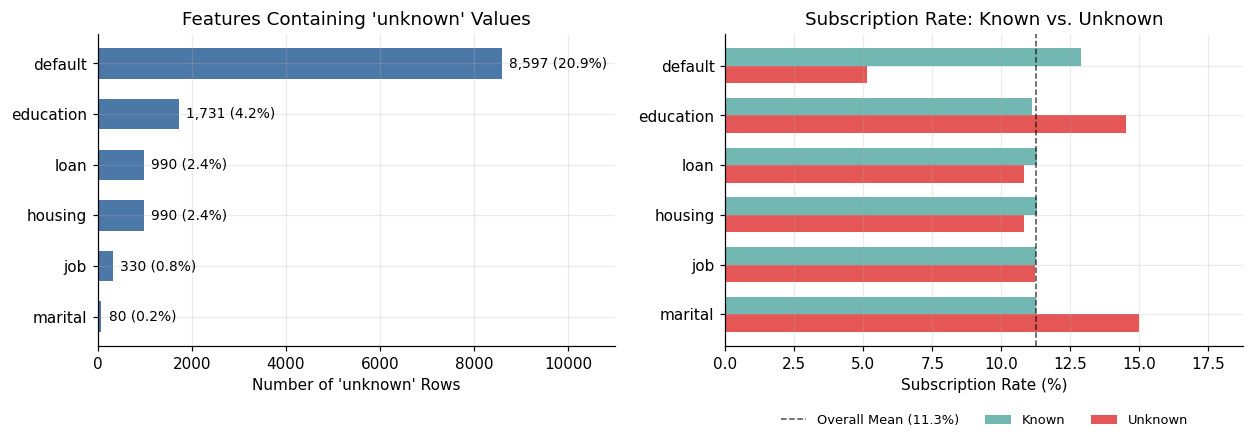

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))

# Left: unknown counts
unk_plot = unk_df.sort_values("unknown_count", ascending=True)
bars = axes[0].barh(unk_plot["feature"], unk_plot["unknown_count"], color=COLORS["no"], height=0.6)
for bar, pct in zip(bars, unk_plot["unknown_pct"]):
    axes[0].text(bar.get_width() + 150, bar.get_y() + bar.get_height() / 2, f"{int(bar.get_width()):,} ({pct:.1f}%)", va="center", fontsize=9)
axes[0].set_xlim(0, unk_plot["unknown_count"].max() * 1.28)
axes[0].set_xlabel("Number of 'unknown' Rows")
axes[0].set_title("Features Containing 'unknown' Values")

# Right: subscription rate known vs unknown
y_pos = np.arange(len(unk_plot))
h = 0.35
axes[1].barh(y_pos + h / 2, unk_plot["yes_rate_if_known (%)"], height=h, color=COLORS["neutral"], label="Known")
axes[1].barh(y_pos - h / 2, unk_plot["yes_rate_if_unknown (%)"], height=h, color=COLORS["yes"], label="Unknown")
axes[1].axvline(11.27, color="black", linestyle="--", linewidth=1, alpha=0.7, label="Overall Mean (11.3%)")
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(unk_plot["feature"])
axes[1].set_xlim(0, unk_plot[["yes_rate_if_known (%)", "yes_rate_if_unknown (%)"]].max().max() * 1.25)
axes[1].set_xlabel("Subscription Rate (%)")
axes[1].set_title("Subscription Rate: Known vs. Unknown")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False, fontsize=8.5)

plt.tight_layout()
plt.show()

**Takeaway**:
- Dropping rows with `"unknown"` would discard **25.98%** of the dataset (10,700 rows).
- Missingness in `default` is **informative (MNAR)**: clients with `default == "unknown"` subscribe at only **5.15%** compared to **12.88%** for `default == "no"` (and `default == "yes"` has only 3 rows, all `"no"`).
- **Decision**: Retain `"unknown"` as a valid categorical level before One-Hot Encoding.

---
## 5. Sentinel Value (`pdays = 999`) & Prior Campaign History

In [9]:
was_contacted = df_full["pdays"] != 999
pdays_summary = pd.DataFrame({
    "count": [ (~was_contacted).sum(), was_contacted.sum() ],
    "share (%)": [ (~was_contacted).mean() * 100, was_contacted.mean() * 100 ],
    "yes_rate (%)": [
        (df_full.loc[~was_contacted, "y"] == "yes").mean() * 100,
        (df_full.loc[was_contacted, "y"] == "yes").mean() * 100,
    ],
}, index=["Never Contacted Before (pdays = 999)", "Previously Contacted (pdays != 999)"]).round(2)

display(pdays_summary)
print("Distribution of pdays when pdays != 999:")
print(df_full.loc[was_contacted, "pdays"].describe().round(2))

pout_summary = df_full.groupby("poutcome")["y"].agg(
    count="count",
    yes_rate=lambda s: round((s == "yes").mean() * 100, 2)
)
display(pout_summary)

Distribution of pdays when pdays != 999:
count    1515.00
mean        6.01
std         3.82
min         0.00
25%         3.00
50%         6.00
75%         7.00
max        27.00
Name: pdays, dtype: float64


,count,share (%),yes_rate (%)
Never Contacted Before (pdays = 999),39673,96.32,9.26
Previously Contacted (pdays != 999),1515,3.68,63.83


,count,yes_rate
poutcome,,
failure,4252,14.23
nonexistent,35563,8.83
success,1373,65.11


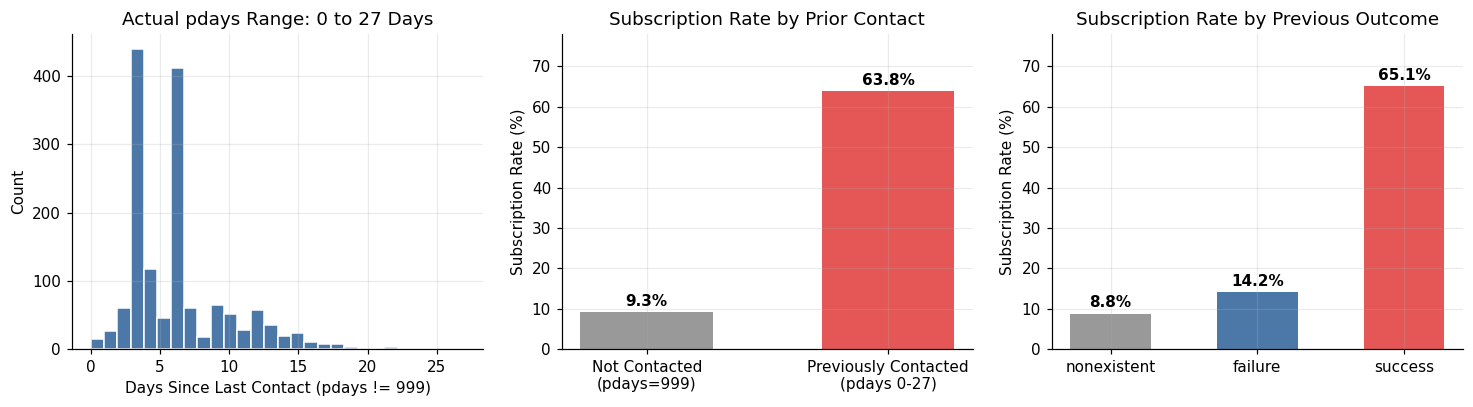

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))

# Panel 1: pdays != 999 histogram
axes[0].hist(df_full.loc[was_contacted, "pdays"], bins=28, color=COLORS["no"], edgecolor="white")
axes[0].set_xlabel("Days Since Last Contact (pdays != 999)")
axes[0].set_ylabel("Count")
axes[0].set_title("Actual pdays Range: 0 to 27 Days")

# Panel 2: conversion by was_contacted
labels = ["Not Contacted\n(pdays=999)", "Previously Contacted\n(pdays 0-27)"]
vals = pdays_summary["yes_rate (%)"].values
bars = axes[1].bar(labels, vals, color=[COLORS["muted"], COLORS["yes"]], width=0.55)
for bar, v in zip(bars, vals):
    axes[1].text(bar.get_x() + bar.get_width() / 2, v + 1.5, f"{v:.1f}%", ha="center", fontweight="bold")
axes[1].set_ylim(0, 78)
axes[1].set_ylabel("Subscription Rate (%)")
axes[1].set_title("Subscription Rate by Prior Contact")

# Panel 3: conversion by poutcome
pout_order = ["nonexistent", "failure", "success"]
pout_vals = [pout_summary.loc[k, "yes_rate"] for k in pout_order]
bars = axes[2].bar(pout_order, pout_vals, color=[COLORS["muted"], COLORS["no"], COLORS["yes"]], width=0.55)
for bar, v in zip(bars, pout_vals):
    axes[2].text(bar.get_x() + bar.get_width() / 2, v + 1.5, f"{v:.1f}%", ha="center", fontweight="bold")
axes[2].set_ylim(0, 78)
axes[2].set_ylabel("Subscription Rate (%)")
axes[2].set_title("Subscription Rate by Previous Outcome")

plt.tight_layout()
plt.show()

**Takeaway**:
- **96.32%** of rows have `pdays = 999`, while all real values lie in `[0, 27]` (median 6 days). Passing raw `999` into Logistic Regression or Neural Networks severely distorts linear scaling and gradients.
- **Decision**: Engineer a binary indicator `was_previously_contacted = (pdays != 999).astype(int)` and replace `999` with `0` (or bin `pdays`) before scaling.

---
## 6. Categorical Features vs. Subscription Rate

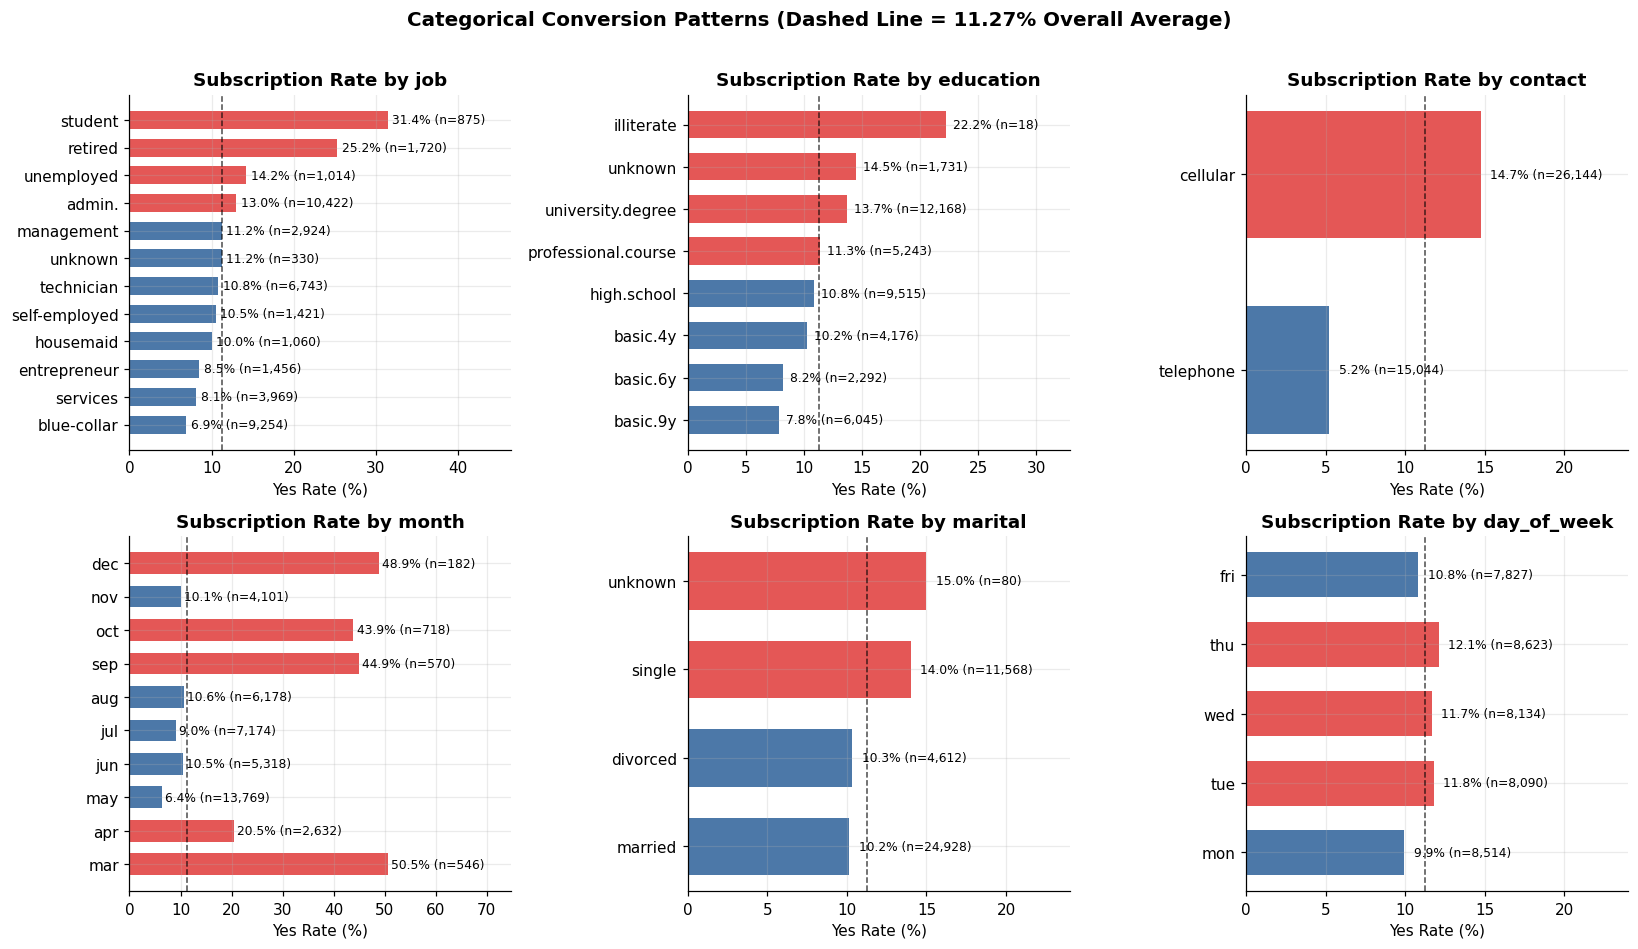

In [11]:
overall_rate = (df_full["y"] == "yes").mean() * 100
plot_cats = ["job", "education", "contact", "month", "marital", "day_of_week"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
axes = axes.ravel()

month_order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
dow_order = ["mon", "tue", "wed", "thu", "fri"]

for ax, col in zip(axes, plot_cats):
    grp = df_full.groupby(col)["y"].agg(
        count="count",
        rate=lambda s: (s == "yes").mean() * 100
    )
    if col == "month":
        grp = grp.reindex([m for m in month_order if m in grp.index])
    elif col == "day_of_week":
        grp = grp.reindex(dow_order)
    else:
        grp = grp.sort_values("rate", ascending=True)

    colors = [COLORS["yes"] if r >= overall_rate else COLORS["no"] for r in grp["rate"]]
    bars = ax.barh(grp.index.astype(str), grp["rate"], color=colors, height=0.65)
    ax.axvline(overall_rate, color="black", linestyle="--", linewidth=1, alpha=0.7)
    ax.set_xlim(0, max(grp["rate"].max() * 1.48, 24))
    for bar, r, cnt in zip(bars, grp["rate"], grp["count"]):
        ax.text(bar.get_width() + 0.6, bar.get_y() + bar.get_height() / 2, f"{r:.1f}% (n={cnt:,})", va="center", fontsize=8)
    ax.set_title(f"Subscription Rate by {col}", fontweight="bold")
    ax.set_xlabel("Yes Rate (%)")

plt.suptitle("Categorical Conversion Patterns (Dashed Line = 11.27% Overall Average)", y=1.01, fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

**Key Observations**:
- **Job**: `student` (31.4%) and `retired` (25.2%) convert at 2–3× the average rate; `blue-collar` (6.9%) is lowest.
- **Contact channel**: `cellular` (14.7%) converts nearly 3× higher than `telephone` (5.2%).
- **Month**: High-volume summer months (`may`, `jul`, `aug`) have lower conversion rates (~6–11%), whereas low-volume months (`mar`, `sep`, `oct`, `dec`) exceed 44–50% — reflecting strong campaign/seasonality effects.

---
## 7. Numeric Features, Distributions & Multicollinearity

In [12]:
num_cols = [c for c in df_full.select_dtypes(include=[np.number]).columns if c != "duration"]
df_full[num_cols].describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]].round(2)

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
campaign,41188.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41188.0,962.48,186.91,0.00,999.00,999.00,999.00,999.00
previous,41188.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41188.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41188.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41188.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41188.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41188.0,5167.04,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


Strongly correlated numeric pairs (|r| > 0.70):
  emp.var.rate    vs cons.price.idx : r = +0.7753
  emp.var.rate    vs euribor3m      : r = +0.9722
  emp.var.rate    vs nr.employed    : r = +0.9070
  euribor3m       vs nr.employed    : r = +0.9452


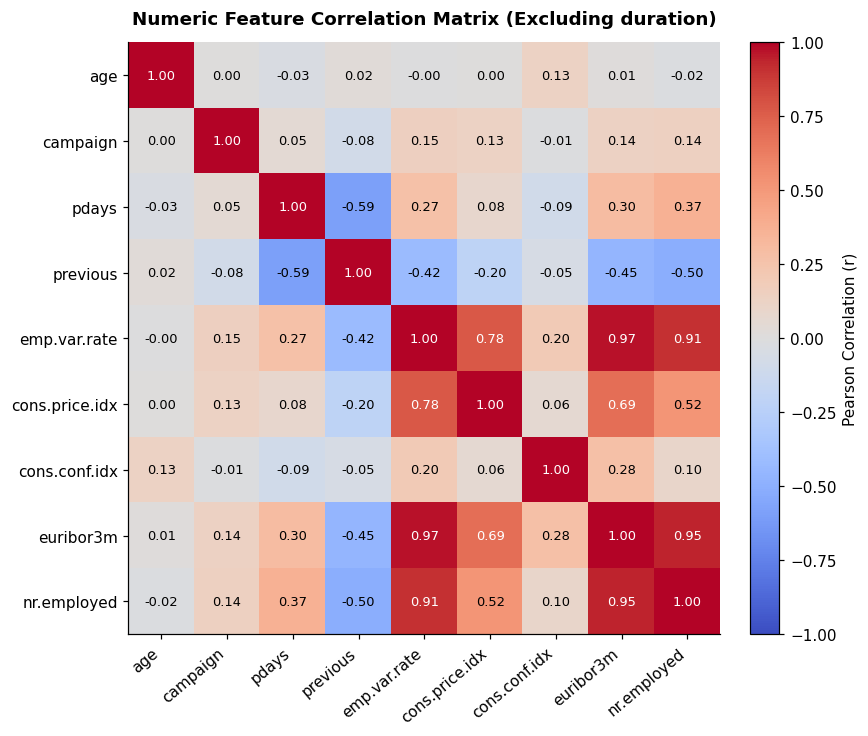

In [13]:
# Correlation matrix of numeric features (excluding duration)
corr = df_full[num_cols].corr()

fig, ax = plt.subplots(figsize=(8.2, 6.8))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(np.arange(len(num_cols)))
ax.set_yticks(np.arange(len(num_cols)))
ax.set_xticklabels(num_cols, rotation=40, ha="right")
ax.set_yticklabels(num_cols)
ax.grid(False)

for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        val = corr.values[i, j]
        text_color = "white" if abs(val) > 0.6 else "black"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", color=text_color, fontsize=8.5)

cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Pearson Correlation (r)")
ax.set_title("Numeric Feature Correlation Matrix (Excluding duration)", pad=12, fontweight="bold")
plt.tight_layout()
plt.show()

print("Strongly correlated numeric pairs (|r| > 0.70):")
for i in range(len(num_cols)):
    for j in range(i + 1, len(num_cols)):
        r = corr.iloc[i, j]
        if abs(r) > 0.70:
            print(f"  {num_cols[i]:15s} vs {num_cols[j]:15s}: r = {r:+.4f}")

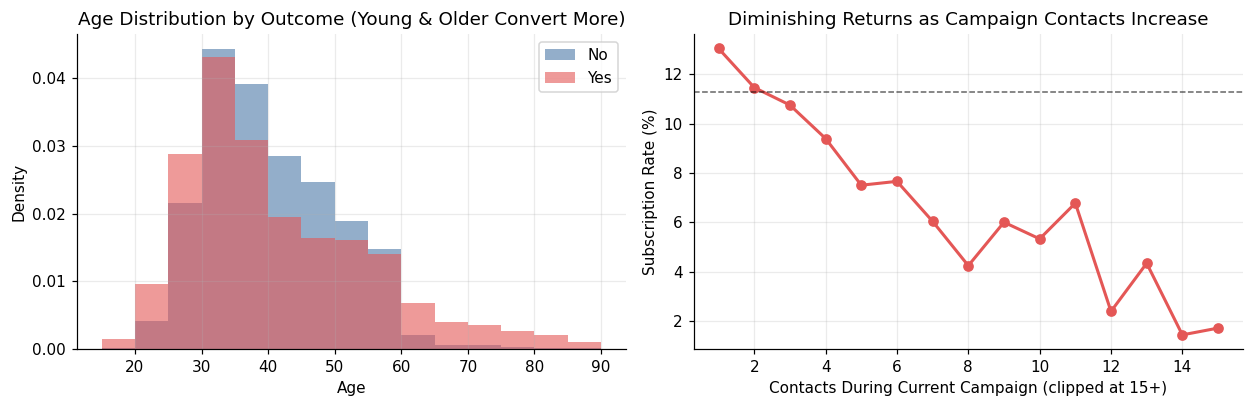

In [14]:
# Age and Campaign distributions by target class
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))

age_bins = np.arange(15, 95, 5)
axes[0].hist(df_full.loc[df_full["y"] == "no", "age"], bins=age_bins, density=True, alpha=0.6, color=COLORS["no"], label="No")
axes[0].hist(df_full.loc[df_full["y"] == "yes", "age"], bins=age_bins, density=True, alpha=0.6, color=COLORS["yes"], label="Yes")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Density")
axes[0].set_title("Age Distribution by Outcome (Young & Older Convert More)")
axes[0].legend()

camp_clipped = df_full["campaign"].clip(upper=15)
camp_rates = df_full.groupby(camp_clipped)["y"].apply(lambda s: (s == "yes").mean() * 100)
axes[1].plot(camp_rates.index, camp_rates.values, marker="o", color=COLORS["yes"], linewidth=2)
axes[1].axhline(overall_rate, color="black", linestyle="--", linewidth=1, alpha=0.6)
axes[1].set_xlabel("Contacts During Current Campaign (clipped at 15+)")
axes[1].set_ylabel("Subscription Rate (%)")
axes[1].set_title("Diminishing Returns as Campaign Contacts Increase")

plt.tight_layout()
plt.show()

**Takeaway**:
- Three macroeconomic indicators are very strongly collinear: `emp.var.rate`–`euribor3m` ($r = 0.97$), `euribor3m`–`nr.employed` ($r = 0.95$), and `emp.var.rate`–`nr.employed` ($r = 0.91$).
- **Modeling impact**: L2-regularized Logistic Regression, Neural Networks, Decision Trees, and XGBoost handle collinearity well for prediction, but Logistic Regression coefficient magnitudes should be interpreted cautiously due to variance inflation.
- `campaign` is heavily right-skewed (max 56 contacts) and exhibits clear diminishing returns after ~3–5 calls.

---
## 8. Dimensionality Check: Do We Need Feature Selection?

In [15]:
df_clean = df_full.drop_duplicates().drop(columns=["duration"]).copy()
df_clean["was_previously_contacted"] = (df_clean["pdays"] != 999).astype(int)
df_clean["pdays_clean"] = df_clean["pdays"].replace(999, 0)
X_raw = df_clean.drop(columns=["y", "pdays"])

X_ohe_full = pd.get_dummies(X_raw, drop_first=False)
X_ohe_drop = pd.get_dummies(X_raw, drop_first=True)

print(f"Unique rows (n):                        {len(X_raw):,}")
print(f"Raw features (after dropping duration): {X_raw.shape[1]}")
print(f"OHE columns (drop_first=False):         {X_ohe_full.shape[1]}  (n/p = {len(X_raw)/X_ohe_full.shape[1]:.1f})")
print(f"OHE columns (drop_first=True):          {X_ohe_drop.shape[1]}  (n/p = {len(X_raw)/X_ohe_drop.shape[1]:.1f})")

Unique rows (n):                        41,176
Raw features (after dropping duration): 20
OHE columns (drop_first=False):         63  (n/p = 653.6)
OHE columns (drop_first=True):          53  (n/p = 776.9)


**Answer to Team Question**:
- Even after full One-Hot Encoding, we only have **53–63 features** for **41,176 samples** ($n / p > 650$).
- **Aggressive upfront feature selection is NOT needed** (and could hurt tree/NN models). Instead, rely on L2 regularization (for LR/NN) and tree regularization (`max_depth`, `min_samples_leaf` for DT/XGBoost).

---
## 9. Leakage-Free Train/Test Split & Resampling Cost Preview

To prevent data leakage, we split **first** (80/20 Stratified, `random_state=42`) and only apply scaling/encoding/resampling inside the training set.

In [16]:
from sklearn.model_selection import train_test_split

y_bin = (df_clean["y"] == "yes").astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X_raw, y_bin, test_size=0.20, stratify=y_bin, random_state=42
)

n_train_neg = int((y_train == 0).sum())
n_train_pos = int((y_train == 1).sum())
n_test_neg = int((y_test == 0).sum())
n_test_pos = int((y_test == 1).sum())

split_preview = pd.DataFrame([
    {"Partition / Strategy": "Test Set (LOCKED — never resampled)", "Total Rows": len(y_test), "No (0)": n_test_neg, "Yes (1)": n_test_pos, "Yes (%)": round(y_test.mean()*100, 2), "Train Size Change": "—"},
    {"Partition / Strategy": "Train — Strategy A (Do Nothing)", "Total Rows": len(y_train), "No (0)": n_train_neg, "Yes (1)": n_train_pos, "Yes (%)": round(y_train.mean()*100, 2), "Train Size Change": "Baseline (1.00x)"},
    {"Partition / Strategy": "Train — Strategy B (Class Weighting)", "Total Rows": len(y_train), "No (0)": n_train_neg, "Yes (1)": n_train_pos, "Yes (%)": round(y_train.mean()*100, 2), "Train Size Change": f"1.00x (pos_weight ≈ {n_train_neg/n_train_pos:.2f})"},
    {"Partition / Strategy": "Train — Strategy C1 (SMOTE / Oversample 1:1)", "Total Rows": n_train_neg * 2, "No (0)": n_train_neg, "Yes (1)": n_train_neg, "Yes (%)": 50.00, "Train Size Change": f"+{(n_train_neg*2/len(y_train)-1)*100:.1f}% (1.77x)"},
    {"Partition / Strategy": "Train — Strategy C2 (Undersample 1:1)", "Total Rows": n_train_pos * 2, "No (0)": n_train_pos, "Yes (1)": n_train_pos, "Yes (%)": 50.00, "Train Size Change": f"{(n_train_pos*2/len(y_train)-1)*100:.1f}% (0.23x)"},
])
split_preview

,Partition / Strategy,Total Rows,No (0),Yes (1),Yes (%),Train Size Change
0,Test Set (LOCKED — never resampled),8236,7308,928,11.27,—
1,Train — Strategy A (Do Nothing),32940,29229,3711,11.27,Baseline (1.00x)
2,Train — Strategy B (Class Weighting),32940,29229,3711,11.27,1.00x (pos_weight ≈ 7.88)
3,Train — Strategy C1 (SMOTE / Oversample 1:1),58458,29229,29229,50.00,+77.5% (1.77x)
4,Train — Strategy C2 (Undersample 1:1),7422,3711,3711,50.00,-77.5% (0.23x)


---
## 10. Summary Checklist for Preprocessing & Modeling

1. **Deduplicate** `bank-additional-full.csv` (41,188 → 41,176 unique rows) before splitting.
2. **Drop `duration`** to eliminate target leakage.
3. **Keep `"unknown"`** as its own categorical level (do not drop the 25.98% of affected rows).
4. **Transform `pdays = 999`** into `was_previously_contacted` + cleaned `pdays`.
5. **Lock one shared 80/20 Stratified Split (`random_state=42`)** for all 4 models and 3 strategies.
6. **Fit `StandardScaler`, `OneHotEncoder`, and `SMOTE` strictly inside training folds** (`imblearn.pipeline.Pipeline`).
7. **Evaluate on the untouched test set** using PR-AUC, ROC-AUC, F1, Precision, Recall, Brier Score (calibration), and training wall-clock time to answer both *"which works best"* and *"what each one costs"*.